In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import json
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv(Path("./raw_data/topopt_data.csv"), sep=";")

In [3]:
# get some information about data
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 22859 entries, 0 to 22858
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   stresses                 22859 non-null  str    
 1   strain_energy_densities  22859 non-null  str    
 2   fixed_dofs               22859 non-null  str    
 3   f                        22859 non-null  str    
 4   volfrac                  22859 non-null  float64
 5   densities                22859 non-null  str    
dtypes: float64(1), str(5)
memory usage: 1.0 MB


In [4]:
def visualize_sample(index):
    
    sample = data.iloc[index]
    stress_string = sample["stresses"]
    stress = np.asarray(json.loads(sample["stresses"])).reshape(64, 64)
    strain_energy_density = np.asarray(json.loads(sample["strain_energy_densities"])).reshape(64, 64)
    densities = np.asarray(json.loads(sample["densities"])).reshape(64, 64)
    volume_fraction = sample["volfrac"]
    f = sample["f"]
    
    
    
    
    
    print(f)
    plt.subplot(1, 3, 1)
    plt.imshow(stress, cmap='plasma', vmin=0, vmax=0.1)
    plt.title("Stress")
    plt.subplot(1, 3, 2)
    plt.imshow(strain_energy_density, cmap='plasma', vmin=0, vmax=0.01)
    plt.title("Strain Energy Density")
    plt.subplot(1, 3, 3)
    plt.imshow(densities, cmap='gray_r')
    plt.title("Densities")
    plt.suptitle(f"Volume Fraction: {volume_fraction}")
    
    
    #######
    # ! Part below was AI generated
    # Overlay load vector and boundary conditions to the plot
    fixed_dofs = np.asarray(json.loads(sample["fixed_dofs"]), dtype=int)
    fixed_nodes = np.unique(fixed_dofs // 2)
    fixed_x, fixed_y = fixed_nodes // 65, fixed_nodes % 65
    force = np.asarray(json.loads(f), dtype=float).ravel()
    if force.size == 3:
        load_nodes = np.array([int(force[0])])
        load_vectors = force[1:].reshape(1, 2)
    elif force.size == 2 * 65 * 65:
        nodal_forces = force.reshape(-1, 2)
        load_nodes = np.flatnonzero(np.any(nodal_forces != 0, axis=1))
        load_vectors = nodal_forces[load_nodes]
    else:
        raise ValueError(f"Unexpected force format: {force.size} entries")

    for ax, field in zip(plt.gcf().axes, (stress, strain_energy_density, densities)):
        # Element arrays are x-major; imshow expects rows along y.
        image = ax.images[0]
        image.set_data(field.T)
        image.set_extent((0, 64, 64, 0))
        ax.scatter(fixed_x, fixed_y, marker="s", s=12, color="tab:blue",
                   label="Fixed nodes", zorder=3, clip_on=False)
        for node, (fx, fy) in zip(load_nodes, load_vectors):
            magnitude = np.hypot(fx, fy)
            if magnitude == 0:
                continue
            x, y = node // 65, node % 65
            ax.annotate("", xy=(x, y),
                        xytext=(x - 8 * fx / magnitude, y - 8 * fy / magnitude),
                        arrowprops=dict(arrowstyle="-|>", color="tab:red", lw=2),
                        zorder=4)
        ax.scatter(load_nodes // 65, load_nodes % 65, s=20, color="tab:red",
                   label="Force", zorder=4)
        ax.set_xlim(-10, 74)
        ax.set_ylim(74, -10)
        ax.legend(fontsize=6)
    plt.show()

[4161, 0.49999999999999933, -0.866025403784439]


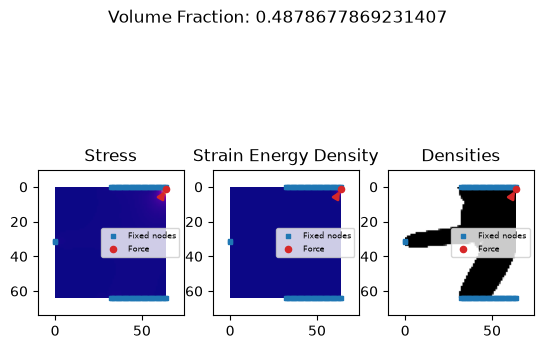

In [37]:
visualize_sample(14)

In [ ]:
# TODO: Augment data by mirroring and rotating

In [10]:
from pathlib import Path
current_dir = Path().cwd()
labeled_data_dir = current_dir / "labeled_data"

In [11]:
# divide the dataset into training, validation and testing sets 
# and store in separate npy files

# set the ratios for training, validation and testing sets
# TODO: Adjust if needed, or select less data
train_ratio = 0.6
val_ratio = 0.2
test_ratio = 0.2

stresses = np.stack([json.loads(sample) for sample in data['stresses']]).astype(np.float32).transpose(0, 2, 1)
strain_energy_densities = np.stack([json.loads(sample) for sample in data['strain_energy_densities']]).astype(np.float32).transpose(0, 2, 1)
volume_fractions = np.asarray(data['volfrac'], dtype=np.float32)
loads = np.stack([json.loads(sample) for sample in data['f']]).astype(np.float32)
fixed_dofs = np.empty(len(data), dtype=object) # fixed_dofs have variable length
for i, sample in enumerate(data["fixed_dofs"]):
    fixed_dofs[i] = np.asarray(json.loads(sample), dtype=np.int64)
#! block for processing densities ai aided since I had a weird format and transposition issue
densities = np.stack([
    np.asarray(json.loads(sample), dtype=np.float32)
    .reshape(64, 64)
    .T
    for sample in data["densities"]
])

stress_train = stresses[:int(train_ratio * len(stresses))]
stress_val = stresses[int(train_ratio * len(stresses)):int((train_ratio + val_ratio) * len(stresses))]
stress_test = stresses[int((train_ratio + val_ratio) * len(stresses)):]

strain_energy_density_train = strain_energy_densities[:int(train_ratio * len(strain_energy_densities))]
strain_energy_density_val = strain_energy_densities[int(train_ratio * len(strain_energy_densities)):int((train_ratio + val_ratio) * len(strain_energy_densities))]
strain_energy_density_test = strain_energy_densities[int((train_ratio + val_ratio) * len(strain_energy_densities)):]

volume_fraction_train = volume_fractions[:int(train_ratio * len(volume_fractions))]
volume_fraction_val = volume_fractions[int(train_ratio * len(volume_fractions)):int((train_ratio + val_ratio) * len(volume_fractions))]
volume_fraction_test = volume_fractions[int((train_ratio + val_ratio) * len(volume_fractions)):]

load_train = loads[:int(train_ratio * len(loads))]
load_val = loads[int(train_ratio * len(loads)):int((train_ratio + val_ratio) * len(loads))]
load_test = loads[int((train_ratio + val_ratio) * len(loads)):]

fixed_dof_train = fixed_dofs[:int(train_ratio * len(fixed_dofs))]
fixed_dof_val = fixed_dofs[int(train_ratio * len(fixed_dofs)):int((train_ratio + val_ratio) * len(fixed_dofs))]
fixed_dof_test = fixed_dofs[int((train_ratio + val_ratio) * len(fixed_dofs)):]

density_train = densities[:int(train_ratio * len(densities))]
density_val = densities[int(train_ratio * len(densities)):int((train_ratio + val_ratio) * len(densities))]
density_test = densities[int((train_ratio + val_ratio) * len(densities)):]

# save data as npy files
np.save(f"{labeled_data_dir}/train/stress_train.npy", stress_train)
np.save(f"{labeled_data_dir}/train/strain_energy_density_train.npy", strain_energy_density_train)
np.save(f"{labeled_data_dir}/train/volume_fraction_train.npy", volume_fraction_train)
np.save(f"{labeled_data_dir}/train/load_train.npy", load_train)
np.save(f"{labeled_data_dir}/train/fixed_dof_train.npy", fixed_dof_train)
np.save(f"{labeled_data_dir}/train/density_train.npy", density_train)

np.save(f"{labeled_data_dir}/val/stress_val.npy", stress_val)
np.save(f"{labeled_data_dir}/val/strain_energy_density_val.npy", strain_energy_density_val)
np.save(f"{labeled_data_dir}/val/volume_fraction_val.npy", volume_fraction_val)
np.save(f"{labeled_data_dir}/val/load_val.npy", load_val)
np.save(f"{labeled_data_dir}/val/fixed_dof_val.npy", fixed_dof_val)
np.save(f"{labeled_data_dir}/val/density_val.npy", density_val)

np.save(f"{labeled_data_dir}/test/stress_test.npy", stress_test)
np.save(f"{labeled_data_dir}/test/strain_energy_density_test.npy", strain_energy_density_test)
np.save(f"{labeled_data_dir}/test/volume_fraction_test.npy", volume_fraction_test)
np.save(f"{labeled_data_dir}/test/load_test.npy", load_test)
np.save(f"{labeled_data_dir}/test/fixed_dof_test.npy", fixed_dof_test)
np.save(f"{labeled_data_dir}/test/density_test.npy", density_test)